# Setup and randomness

## Session 2: Probability and computational foundations

Use the Week 1 page in ELO (Session 2 section), notes, and exercise sheet.
We investigate a real random variable $U\sim\mathrm{Uniform}[0,1]$, with
mean $\mu=\mathbb E[U]=1/2$ and variance $\sigma^2=\operatorname{Var}(U)=1/12$.
Write $\sigma=\sqrt{\sigma^2}$. Predict first, run the supplied code, and explain the result.
This notebook develops F1–F4; do not complete a second copy of those tasks.

**Week 1 timing:** Sessions 1 and 2 take place on the same day, separated
by a 15-minute rest break. No setup or homework is required during that gap.
Session 2 uses an instructor-led demonstration without assuming completed
student setup or Session 1 homework. Complete both follow-up blocks after
Sessions 1–2 and before Session 3 the next week.

**Session 1 setup block:** After the weekly pair, run only the first code cell
below. Stop before **Predict** for this check. Allow at most 15 minutes for
access, installation, and the check together. See the
Week 1 page in ELO (Session 1 follow-up) and `Week01-Setup.txt`. Then continue A–D in the separate
Session 2 follow-up allocation below; do not count the setup twice.

**Session 2 route:** The instructor demonstrates A–D during class. After the
weekly pair and the setup block above, follow sections A–D in order. The 45-minute practice allocation includes 10 minutes finishing
the worksheet, 25 minutes revisiting this notebook and changing settings,
and 10 minutes of peer discussion and your own explanation. Section E is an
optional CLT illustration for the lecture, with no extra homework requirement.
No exercise requires an assessed-project result.

In [5]:
import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

print('Python', sys.version.split()[0])
print('NumPy', np.__version__)
print('Matplotlib', matplotlib.__version__)

Python 3.13.14
NumPy 2.3.5
Matplotlib 3.11.2


## Predict

Before continuing in Session 2, predict whether two freshly created generators
with the same seed produce the same six numbers. Does repeating that sequence
give a new independent repetition?

## A. Probability and small arrays

All random variables in a joint calculation are defined on a common probability
space $(\Omega,\mathcal F,\Pr)$, as defined in the notes. For
$U\sim\mathrm{Uniform}[0,1]$, define the events
$A=\{\omega\in\Omega:U(\omega)<1/4\}=\{U<1/4\}$ and $B=\{U<1/2\}$.
Calculate $\Pr(A)$, $\Pr(B)$, $\Pr(A\cap B)$, and
$\Pr(A\mid B)=\Pr(A\cap B)/\Pr(B)$ on paper (S2.1); the conditional formula
requires $\Pr(B)>0$. Are $A$ and $B$ independent, meaning
$\Pr(A\cap B)=\Pr(A)\Pr(B)$? Compare with $A$ and $C=\{V<1/2\}$,
where $V$ has the same law as $U$ and is independent of $U$.

The next cell uses fixed illustrative data, not a random sample for establishing
theoretical moments. Predict its shape, mean, squared deviations, and sample
variance (S2.3). A NumPy square is elementwise; mean reduces the array.

For fixed values $u_1,\ldots,u_n\in\mathbb R$ and an integer $n\geq2$, define
$$
\overline u_n=\frac1n\sum_{i=1}^n u_i,\qquad
s_n^2=\frac1{n-1}\sum_{i=1}^n(u_i-\overline u_n)^2,\qquad s_n=\sqrt{s_n^2}.
$$
The cell has $n=4$ and $(u_1,u_2,u_3,u_4)=(0.2,0.4,0.6,0.8)$.
These are observed summaries. Under an iid model with finite variance,
$s_n/\sqrt n$ estimates the SE of the sample mean. The fixed data alone do
not establish that sampling model.

In [6]:
example = np.array([0.2, 0.4, 0.6, 0.8])
deviations = example - example.mean()
sample_variance = example.var(ddof=1)
print('Shape:', example.shape)
print('Mean:', example.mean())
print('Squared deviations:', deviations**2)
print('Sum of squared deviations:', np.sum(deviations**2))
print('Sample variance:', sample_variance)
print('Sample SD:', np.sqrt(sample_variance))
print('Estimated SE under an iid model:', np.sqrt(sample_variance / example.size))
print('Fraction below 0.5:', (example < 0.5).mean())
assert np.isclose(example.mean(), 0.5)
assert np.isclose(sample_variance, 1 / 15)

Shape: (4,)
Mean: 0.5
Squared deviations: [0.09 0.01 0.01 0.09]
Sum of squared deviations: 0.2
Sample variance: 0.06666666666666667
Sample SD: 0.2581988897471611
Estimated SE under an iid model: 0.12909944487358055
Fraction below 0.5: 0.5


For the displayed array, `example < 0.5` produces `[True, True, False, False]`.
In its arithmetic mean, `True` counts as 1 and `False` as 0. Thus
`(example < 0.5).mean()` is $(1+1+0+0)/4=0.5$: the **fraction of all four
observations below the threshold**. It does not average the selected values
$0.2,0.4$, whose mean would be $0.3$. Its equality to `example.mean()` in
this example is a coincidence; the two operations summarize different things.
For observations $u_1,\ldots,u_n$, the Boolean fraction is
$n^{-1}\sum_{i=1}^n\mathbf1_{(-\infty,0.5)}(u_i)$, where the indicator is 1 on
the stated interval and 0 outside it. Under the uniform sampling model,
it estimates $\Pr(U<0.5)$ rather than $\mathbb E[U]$.

The denominator for sample variance
with `ddof=1` is $n-1$, whereas NumPy's default `ddof=0` uses $n$.
Neither convention changes the uniform model variance $1/12$.
For random iid inputs $U_1,\ldots,U_n$, replacing the fixed $u_i$ by $U_i$
in the formulas gives the random statistics $\overline U_n,S_n^2,S_n$.
Under finite variance, $\mathbb E[S_n^2]=\sigma^2$; $S_n$ need not be unbiased
for $\sigma$. An observed value $s_n=S_n(\omega)$ is distinct from $S_n$.

## B. Reproducibility and the generator state

State your prediction from above before executing this cell (F3 and S2.4).
The program records software versions because a seed alone does not guarantee
identical results across different software versions.

In [7]:
first = np.random.default_rng(2026).uniform(size=6)
repeated = np.random.default_rng(2026).uniform(size=6)
rng = np.random.default_rng(2026)
block_1 = rng.uniform(size=6)
block_2 = rng.uniform(size=6)
print('New generator, same seed:', np.array_equal(first, repeated))
print('One generator, successive blocks:', block_1, block_2, sep='\n')

# Deliberate bug: restarting the generator in every repetition.
bad_means = np.array([
    np.random.default_rng(2026).uniform(size=100).mean()
    for _ in range(6)
])
# Approximate independent repetitions with distinct child streams.
child_seeds = np.random.SeedSequence(2026).spawn(6)
good_means = np.array([
    np.random.default_rng(child).uniform(size=100).mean()
    for child in child_seeds
])
print('Restarted seed means:', bad_means)
print('Distinct-stream means:', good_means)
assert np.array_equal(first, repeated)
assert np.all(bad_means == bad_means[0])

New generator, same seed: True
One generator, successive blocks:
[0.17893481 0.63991317 0.4672684  0.37050053 0.35491733 0.79051825]
[0.90514384 0.17735319 0.6527848  0.29830277 0.9669622  0.91985016]
Restarted seed means: [0.5187482 0.5187482 0.5187482 0.5187482 0.5187482 0.5187482]
Distinct-stream means: [0.52016648 0.52261505 0.47382567 0.49015478 0.57114025 0.5192979 ]


Explain why the first set of six means cannot reveal variability across
independent repetitions. Different numerical values alone also do not prove
independence. A pseudo-random generator is deterministic: a seed initializes
its state and each call updates that state. The iid probability model describes
the ideal experiment that this computation approximates. Distinct seeds or child
streams do not prove mathematical independence. Repeating the same seeded
computation supplies no new evidence about variability under that model.

## C. Observations and one running average

In the ideal model, let $(U_i)_{i\in\mathbb N}$ be an infinite iid sequence with
law $\mathrm{Uniform}[0,1]$, where $\mathbb N=\{1,2,\ldots\}$.
For $n\in\mathbb N$, define $\overline U_n=n^{-1}\sum_{i=1}^n U_i$.
Its realized value is $\overline u_n=n^{-1}\sum_{i=1}^n u_i$,
where $u_i=U_i(\omega)$. From F1,
$$
\mathbb E[\overline U_n]=\mu=\tfrac12,\qquad
\operatorname{Var}(\overline U_n)=\frac{\sigma^2}{n}=\frac1{12n},\qquad
\operatorname{SE}(\overline U_n)=\frac{\sigma}{\sqrt n}.
$$
SE is the standard deviation of the random estimator. Predict its value for
$n=2000$. The computed $s_n/\sqrt n$ estimates this SE; it is neither the
true SE nor the realized error $\overline u_n-\mu$.

**One complete run:** generate $n=2000$ draws, then average them to obtain
**one final estimate** of the fixed target $\mu=1/2$. The 2000 array entries
in `draws` are observations, not 2000 complete-run estimates. The running
means use prefixes of this same array: draw 1 alone, then draws 1–2, and
so on. The last prefix mean equals that run's final estimate.

Mean: 0.520077
Sample SD of observations: 0.291516
Estimated SE of the mean: 0.006519
Theoretical SE: 0.006455


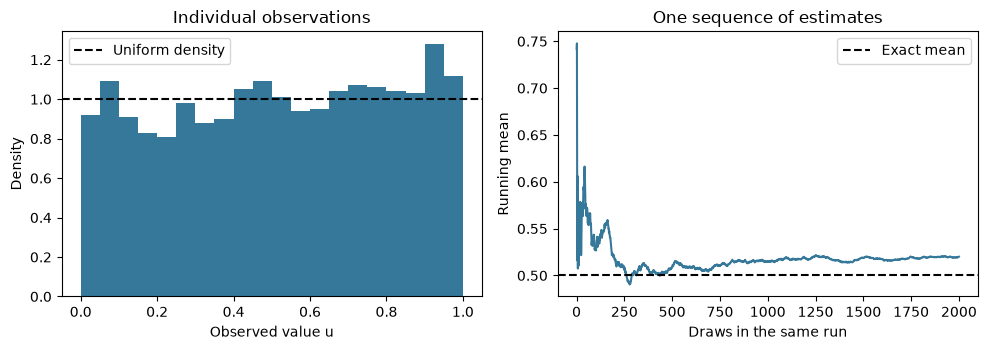

In [8]:
observation_seed = 47
n_observations = 2000
draws = np.random.default_rng(observation_seed).uniform(size=n_observations)
counts = np.arange(1, n_observations + 1)
running_mean = np.cumsum(draws) / counts
estimated_sd = draws.std(ddof=1)
estimated_se = estimated_sd / np.sqrt(n_observations)
print(f'Mean: {draws.mean():.6f}')
print(f'Sample SD of observations: {estimated_sd:.6f}')
print(f'Estimated SE of the mean: {estimated_se:.6f}')
print(f'Theoretical SE: {np.sqrt(1 / (12*n_observations)):.6f}')

fig_observations, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(draws, bins=np.linspace(0, 1, 21), density=True, color='#36789a')
axes[0].axhline(1, color='black', linestyle='--', label='Uniform density')
axes[0].set(xlabel='Observed value u', ylabel='Density', title='Individual observations')
axes[0].legend()
axes[1].plot(counts, running_mean, color='#36789a')
axes[1].axhline(0.5, color='black', linestyle='--', label='Exact mean')
axes[1].set(xlabel='Draws in the same run', ylabel='Running mean', title='One sequence of estimates')
axes[1].legend()
fig_observations.tight_layout()
plt.show()
assert np.all((draws >= 0) & (draws < 1))
assert np.isclose(running_mean[-1], draws.mean())

1. Which panel shows observations and which shows estimates?
2. Can the absolute error of the running mean increase at the next draw?
3. Would a single smooth-looking trace prove a law of large numbers?

Read the displays as follows; these explanations support the same three questions.

| Display | Horizontal axis | Vertical axis | What contributes to it? |
| --- | --- | --- | --- |
| Left: raw-observation histogram | Observed value $u$ | Density height | The 2000 individual draws from one run |
| Right: running mean | Prefix length $k=1,\ldots,2000$ | $\overline u_k=k^{-1}\sum_{i=1}^k u_i$ | Successive prefixes of that same run |

The prefix means share inputs and are dependent under this iid uniform model.
They are not independent repetitions. A running mean can move away from $1/2$
after a new draw. Its dashed line marks the exact target, not a fitted mean.

A histogram bin of width $w>0$ containing $m$ out of $n$ observations has
height $m/(nw)$; its **area**, height times width, is the observed fraction
$m/n$. Here the 20 bins have width $0.05$ and cover all generated values in
$[0,1]$. Their total area is 1. The dashed uniform density is 1, so a bin of
width $0.05$ has model probability $0.05$, not probability 1. Heights can
exceed 1; a density height is not a point probability. The theoretical law
assigns probability zero to any specified single value.

The notebook's running-mean axis is automatically scaled to the displayed
values; always read its ticks rather than judging error from visual height
alone. The lecture's running-mean plot uses the full $[0,1]$ vertical range.
Neither display drops values from the computed estimate. Section E separately
explains its deliberately restricted histogram range.

**Weak LLN for this model:** for every $\varepsilon>0$,
$$
\lim_{n\to\infty}\Pr(|\overline U_n-\mu|>\varepsilon)=0.
$$
This is convergence in probability to $\mu$. The more general iid theorem in
the notes assumes a finite absolute expectation. A finite trace illustrates
behavior but does not prove this limit or a monotone decrease of realized error.

## D. Repeated estimates and sample size

**Prediction (F2):** How should the standard error change from $n=100$ to $n=400$?
Keep separate the integer number of draws in one run ($n\geq1$) and the
integer number of whole runs ($R\geq2$):

**One run → $n$ draws → one mean. Repeating the whole run $R$ times → $R$ means
estimating the same fixed target $\mu=1/2$.**

For fixed $n$, let $U_i^{(r)}$, $i=1,\ldots,n$, $r=1,\ldots,R$, be mutually
independent uniform random variables. Run $r$ returns
$T_n^{(r)}=n^{-1}\sum_{i=1}^nU_i^{(r)}$. Thus
$T_n^{(1)},\ldots,T_n^{(R)}$ are independent copies of $\overline U_n$.
Write $t_r=T_n^{(r)}(\omega)$ for $r=1,\ldots,R$. The empirical SD is
$$
\overline t_R=\frac1R\sum_{r=1}^R t_r,\qquad
s_{\mathrm{rep}}=\sqrt{\frac1{R-1}\sum_{r=1}^R(t_r-\overline t_R)^2}.
$$
This spread of the $R$ observed means estimates
$\operatorname{SE}(T_n^{(1)})=\sigma/\sqrt n$: uncertainty of **one**
$n$-draw run. Whole-run repetition lets us examine that estimator's sampling
variability and compare it with the theoretical SE.

Increasing $n$ reduces the true SE of one run as $\sigma/\sqrt n$.
Increasing $R$ provides more evidence for estimating this same spread;
it does not change the single-run SE or guarantee that every empirical SD
will be closer to it than the previous one.

**Do not divide $s_{\mathrm{rep}}$ by $\sqrt R$ to estimate the SE of one run.**
That division estimates the SE of a different estimator:
$G_{n,R}=R^{-1}\sum_{r=1}^R T_n^{(r)}$, whose observed value is
$\overline t_R$. Under the stated independence model,
$\operatorname{SE}(G_{n,R})=\sigma/\sqrt{nR}$. It is algebraically the
mean of all $nR$ draws pooled together; its computational budget is $nR$.
It still estimates the same fixed target $\mu$. We calculate its observed
value as a summary, but the experiment's empirical SD concerns one $n$-draw run.

The function below requires $n\geq2$ and uses one child stream per whole run.
It returns a **$3\times400$ array of complete-run means**, not raw draws:

| Array row | Draws in each run | Entries in that row |
| --- | --- | --- |
| `estimates[0, :]` | $n=100$ | 400 means, each averaging its own 100 draws |
| `estimates[1, :]` | $n=400$ | 400 means, each averaging its own 400 draws |
| `estimates[2, :]` | $n=1600$ | 400 means, each averaging its own 1600 draws |

Column indices `0` to `399` label the 400 repetitions within a row. For example,
`estimates[1, 0]` is the mean from the first 400-draw run. The groups use
distinct child streams, so matching column labels do not mean that groups
share random inputs in this baseline experiment. Every entry estimates $1/2$.
For one row `values`, `values.mean()` is $\overline t_R$, while
`values.std(ddof=1)` is $s_{\mathrm{rep}}$.

Estimate-array shape: (3, 400)
n= 100: mean=0.499327, empirical SD=0.027172, theoretical SE=0.028868
n= 400: mean=0.499911, empirical SD=0.015156, theoretical SE=0.014434
n=1600: mean=0.500223, empirical SD=0.007232, theoretical SE=0.007217


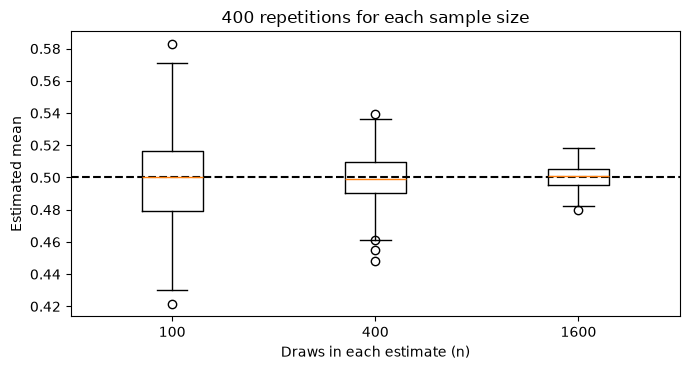

In [9]:
def repeat_means(sample_sizes, repetitions, root_seed):
    sizes = np.asarray(sample_sizes)
    if sizes.ndim != 1 or sizes.size == 0:
        raise ValueError('sample_sizes must be a nonempty one-dimensional sequence')
    if not np.issubdtype(sizes.dtype, np.integer) or np.any(sizes < 2):
        raise ValueError('sample sizes must be integers of at least two')
    if not isinstance(repetitions, (int, np.integer)) or repetitions < 2:
        raise ValueError('use at least two repetitions')
    seeds = np.random.SeedSequence(root_seed).spawn(sizes.size * repetitions)
    estimates = np.empty((sizes.size, repetitions))
    for j, size in enumerate(sizes):
        for k in range(repetitions):
            rng = np.random.default_rng(seeds[j * repetitions + k])
            estimates[j, k] = rng.uniform(size=int(size)).mean()
    return estimates

sample_sizes = np.array([100, 400, 1600])
repetitions = 400
root_seed = 2026
estimates = repeat_means(sample_sizes, repetitions, root_seed)
theoretical_se = np.sqrt(1 / (12 * sample_sizes))
print('Estimate-array shape:', estimates.shape)
for size, values, se in zip(sample_sizes, estimates, theoretical_se):
    print(f'n={size:4d}: mean={values.mean():.6f}, empirical SD={values.std(ddof=1):.6f}, theoretical SE={se:.6f}')

fig_repetitions, ax = plt.subplots(figsize=(7, 3.8))
ax.boxplot(estimates.T, tick_labels=sample_sizes)
ax.axhline(0.5, color='black', linestyle='--')
ax.set(xlabel='Draws in each estimate (n)', ylabel='Estimated mean',
       title=f'{repetitions} repetitions for each sample size')
fig_repetitions.tight_layout()
plt.show()

In this graph, the horizontal labels are the three values of $n$, not time
or repetition number. The vertical axis contains **complete-run mean estimates**,
not individual uniform draws. Each box summarizes 400 entries from one row
of `estimates`; `.T` transposes the array to the plotting function's column
convention. The dashed line is the same target $1/2$ for all three groups.
A dot plot of these entries would show one dot per complete-run mean.
Narrower vertical spread for larger $n$ concerns the distribution of estimates.

The box runs from the sample 25th percentile $Q_1$ to the 75th percentile $Q_3$;
its internal line is the sample median (50th percentile). These use the linear
sample-quantile convention defined in Session 1 notes, Section 5.1.
The interquartile range is $I=Q_3-Q_1$. The whiskers reach the most extreme
observed values in $[Q_1-1.5I,Q_3+1.5I]$. Dots beyond the whiskers are still
valid results. These boxes are not confidence intervals.
The empirical SD $s_{\mathrm{rep}}$ varies across repeated experiments because
$R$ is finite; no individual experiment must reproduce the theoretical SE exactly.

**Your controlled changes (within the 25-minute notebook allocation):**
Record a prediction before the next cell. It first changes only the root seed,
then changes only the middle sample size while restoring the original seed.
Compare with the original summaries. Using the same streams across settings
can make comparisons dependent; only the repetitions within each setting are
intended as independent. Record all settings, including results you did not expect.

In [10]:
changed_seed = 2027
changed_sizes = np.array([100, 900, 1600])
new_seed_estimates = repeat_means(sample_sizes, repetitions, changed_seed)
new_size_estimates = repeat_means(changed_sizes, repetitions, root_seed)
for label, sizes, values in [
    ('Original', sample_sizes, estimates),
    ('Changed seed only', sample_sizes, new_seed_estimates),
    ('Changed middle n only', changed_sizes, new_size_estimates),
]:
    print(label)
    for size, row in zip(sizes, values):
        print(f'  n={size:4d}: mean={row.mean():.6f}, empirical SD={row.std(ddof=1):.6f}, theoretical SE={np.sqrt(1/(12*size)):.6f}')

Original
  n= 100: mean=0.499327, empirical SD=0.027172, theoretical SE=0.028868
  n= 400: mean=0.499911, empirical SD=0.015156, theoretical SE=0.014434
  n=1600: mean=0.500223, empirical SD=0.007232, theoretical SE=0.007217
Changed seed only
  n= 100: mean=0.497740, empirical SD=0.028938, theoretical SE=0.028868
  n= 400: mean=0.499768, empirical SD=0.014286, theoretical SE=0.014434
  n=1600: mean=0.500204, empirical SD=0.007257, theoretical SE=0.007217
Changed middle n only
  n= 100: mean=0.499327, empirical SD=0.027172, theoretical SE=0.028868
  n= 900: mean=0.499794, empirical SD=0.010118, theoretical SE=0.009623
  n=1600: mean=0.500223, empirical SD=0.007232, theoretical SE=0.007217


**Explain:** Which theoretical quantities changed? Which numerical summaries
changed even when the probability model did not? How close is the empirical
ratio of SDs for n=100 and n=400 to your predicted ratio? Why need it not be exact?

**Stop here for required notebook practice.** In the ten-minute discussion block,
compare one claim with a peer and write your own three-sentence explanation
covering SD versus SE, seed handling, and the effect of quadrupling n. Identify
one limitation within those sentences. This is F4, not an extra written task.
Sharing through the course collaboration link announced in ELO
is optional. If setup is unavailable, use the table in the notes, mark it as
supplied evidence, and write predictions instead of claiming to have run code.

## E. Optional lecture illustration: the iid central limit theorem

Let $(X_i)_{i\in\mathbb N}$ be an infinite iid sequence of real random variables
with $\mu=\mathbb E[X_1]$ and $0<\sigma^2=\operatorname{Var}(X_1)<\infty$.
For $n\in\mathbb N$, put $\overline X_n=n^{-1}\sum_{i=1}^n X_i$,
$\sigma=\sqrt{\sigma^2}$, and $Z_n=\sqrt n(\overline X_n-\mu)/\sigma$.
The standard normal law $\mathcal N(0,1)$ has density $\phi$ and cumulative
distribution function (CDF) $\Phi$:
$$
\phi(t)=\frac1{\sqrt{2\pi}}e^{-t^2/2},\qquad
\Phi(t)=\int_{-\infty}^t\phi(s)\,ds,\qquad t\in\mathbb R.
$$
Here $\pi$ is the circle constant and $s$ is an integration variable.
The iid CLT states
$$
\lim_{n\to\infty}\Pr(Z_n\leq t)=\Phi(t)\quad\text{for every }t\in\mathbb R.
$$
This is convergence in distribution to the standard normal law. It uses the
true $\sigma$, not an estimated sample SD. It supplies no universal finite
sample size that guarantees an accurate normal approximation.

For the plotted uniform example, $\mu=1/2$ and $\sigma^2=1/12$.
The code compares $n=1$ and $n=100$, using $R=400$ realizations in each panel.
The horizontal axis now contains **standardized means**, and the vertical axis
is density. The left panel uses 400 standardized one-draw means; the right
uses 400 standardized means of 100 draws each. This does not make the individual
uniform observations normal. Each histogram bin height is its count divided
by $R$ and its width, so bin area is a fraction of all $R=400$ realizations.
The displayed interval is restricted to $[-4,4]$. Its title reports how many
values lie outside that interval; the denominator still includes them. If
values are omitted from view, the visible bars' total area is less than 1.
This display choice changes neither the generated values nor any estimate.
The orange curve is $\phi$, with no fitted parameters. These finite plots
illustrate the theorem without proving it.

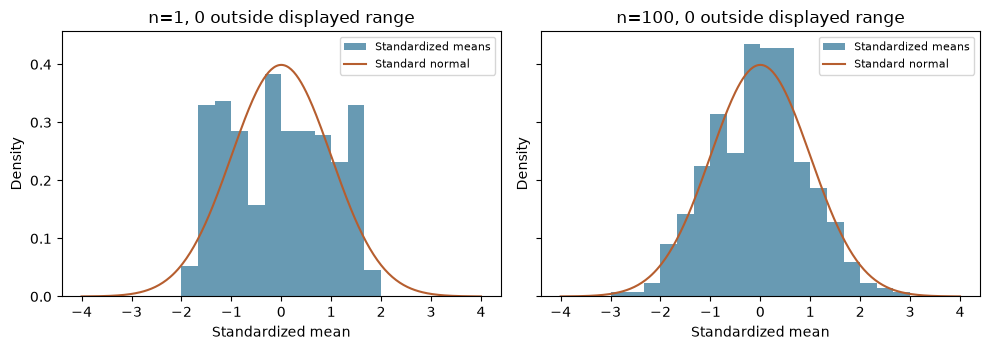

In [11]:
sigma = np.sqrt(1 / 12)
single_draws = np.random.default_rng(9901).uniform(size=repetitions)
z_one = (single_draws - 0.5) / sigma
z_hundred = np.sqrt(sample_sizes[0]) * (estimates[0] - 0.5) / sigma
z_grid = np.linspace(-4, 4, 321)
normal_density = np.exp(-z_grid**2 / 2) / np.sqrt(2*np.pi)
z_edges = np.linspace(-4, 4, 25)
fig_clt, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharex=True, sharey=True)
for ax, z, label in zip(axes, [z_one, z_hundred], ['n=1', 'n=100']):
    ax.hist(z, bins=z_edges, weights=np.full(z.size, 1/(z.size*(z_edges[1]-z_edges[0]))),
            color='#36789a', alpha=0.75, label='Standardized means')
    ax.plot(z_grid, normal_density, color='#b65e2f', label='Standard normal')
    outside = np.count_nonzero((z < z_edges[0]) | (z > z_edges[-1]))
    ax.set(xlabel='Standardized mean', ylabel='Density', title=f'{label}, {outside} outside displayed range')
    ax.legend(fontsize=8)
fig_clt.tight_layout()
plt.show()

### Sources and next steps

NumPy documents [Generator and explicit seeds](https://numpy.org/doc/stable/reference/random/generator.html),
[child random streams](https://numpy.org/doc/stable/reference/random/parallel.html),
and [standard deviation and ddof](https://numpy.org/doc/stable/reference/generated/numpy.std.html).
Matplotlib documents the [boxplot convention](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.boxplot.html).
For mathematical definitions and theorem assumptions, use the
[Session 1 notes](Session01-Notes.pdf) and
[Session 2 notes](Session02-Notes.pdf).
The uniform examples and experimental design are supplied course examples.
Keep software versions, seeds, sample sizes, and repetition counts with an experiment.
Later sessions develop confidence intervals and dependent-sample uncertainty.